# 2. Clean the data and build the weekly factor

This notebook reads `data/raw/` and saves `data/processed/weekly.csv`.

Steps:
1. Load the daily closes of the 14 pairs into one table
2. Drop unfinished days (anything on or after the download date)
3. Remove one-day price errors (a jump that is fully reversed the next day)
4. Rebuild AUDUSD before May 2006 as AUDJPY / USDJPY, and check it against the real one
5. Add the 1999 to 2004 history from FRED
6. Align dates and fill small gaps forward only
7. Keep Friday closes and compute weekly returns
8. Build the factor: the equal-weight basket of all 14 pairs, held long
9. Load the rates and the VIX, lag the monthly rates, add the basket's carry
10. Daily factor returns and weekly realised volatility
11. Save the weekly table and run the checks

In [15]:
# JupyterLab on Nuvolos starts the kernel in /files, while VS Code starts it in the notebook's
# folder. The notebooks need to run from code/ to find helpers.py and ../data, so this cell
# looks for that folder and moves into it. Adapted from a fix shared by a classmate.
import os
from pathlib import Path

if not Path("helpers.py").exists():
    found = [p.parent for p in Path.cwd().glob("**/code/helpers.py")
             if (p.parent / "05_figures.ipynb").exists()]
    if len(found) != 1:
        raise FileNotFoundError(f"Cannot find a single project code folder under {Path.cwd()}: {found}")
    os.chdir(found[0])
print("Working directory:", Path.cwd())

Working directory: /Users/robertoberardi/Desktop/HEC/3 Semester/ada-fx-project/trend-following-fx-risk-factor/code


In [16]:
import os

import numpy as np
import pandas as pd

import helpers

os.makedirs(helpers.PROCESSED, exist_ok=True)

## 1. Load the daily closes

In [17]:
# Yahoo saves each file with three header rows (price type, ticker, date).
# header=[0, 1] reads the first two as column names, the third becomes the index name.
def load_close(name):
    df = pd.read_csv(f"{helpers.RAW}/{name}.csv", header=[0, 1], index_col=0, parse_dates=True)
    return df["Close"].iloc[:, 0]

closes = pd.DataFrame({p: load_close(p) for p in helpers.ALL_PAIRS})
sp500 = load_close("SP500").rename("SP500")

print(closes.shape)
closes.tail(3)

(5695, 14)


,CADJPY,AUDUSD,USDJPY,EURUSD,EURCHF,GBPJPY,USDCAD,GBPUSD,EURGBP,GBPCHF,CHFJPY,AUDJPY,EURJPY,USDCHF
Date,,,,,,,,,,,,,,
2026-11-12,112.114998,0.684280,159.733994,1.109521,0.92337,212.065002,1.42479,1.327669,0.83564,1.1048,191.912003,109.293999,177.223007,0.83229
2026-11-13,112.089996,0.680690,159.875000,1.105021,0.92369,211.535995,1.42610,1.323136,0.83502,1.1060,191.218994,108.820999,176.658997,0.83593
2026-11-16,NaN,0.674673,NaN,1.100715,0.92342,210.455002,NaN,1.318722,0.83453,NaN,NaN,NaN,175.638000,NaN


## 2. Drop unfinished days

In [18]:
# The download date is saved by the first notebook. Prices on or after that day
# are not final closes, so we drop them. The sample also stops at the fixed end date
# in helpers.py, so a later download gives the same weeks.
with open(f"{helpers.RAW}/download_date.txt") as f:
    download_date = pd.Timestamp(f.read().strip())
cutoff = min(download_date, pd.Timestamp(helpers.END))

closes = closes[closes.index < cutoff]
sp500 = sp500[sp500.index < cutoff]

print("Download date:", download_date.date())
print("Last day kept:", closes.index.max().date())

Download date: 2026-11-16
Last day kept: 2026-11-13


## 3. Remove one-day price errors

In [19]:
# Yahoo's FX history contains a few bad prints: a jump of several percent on one day
# that is fully reversed the next day (for example EURUSD +17% on 8 Dec 2008, -13% on 9 Dec).
# A real move does not reverse like that. Rule: a daily move above 3% whose next-day move
# cancels at least 70% of it is treated as an error. That price is removed and replaced by
# the previous day's price.
ret = closes.pct_change()
next_ret = ret.shift(-1)
is_error = (ret.abs() > 0.03) & ((ret + next_ret).abs() < 0.3 * ret.abs())

print("Price errors found per pair:")
print(is_error.sum().to_string())
print("Total:", is_error.sum().sum())

closes = closes.mask(is_error).ffill()

# The largest daily moves that remain should all be real events
# (October 2008, SNB floor in September 2011, SNB floor removal in January 2015, Brexit)
remaining = closes.pct_change().stack()
print()
print("Largest moves left in the data:")
print(remaining[remaining.abs() > 0.08].sort_values().to_string())

Price errors found per pair:
CADJPY    5
AUDUSD    3
USDJPY    3
EURUSD    5
EURCHF    1
GBPJPY    4
USDCAD    1
GBPUSD    0
EURGBP    1
GBPCHF    2
CHFJPY    2
AUDJPY    8
EURJPY    0
USDCHF    1
Total: 36

Largest moves left in the data:
Date              
2015-01-16  EURCHF   -0.172052
            GBPCHF   -0.164476
            USDCHF   -0.161473
2008-10-24  AUDJPY   -0.105892
2008-10-06  AUDJPY   -0.102715
2016-06-27  GBPJPY   -0.100425
2008-10-28  EURJPY    0.082709
2011-09-07  GBPCHF    0.086451
2008-10-28  GBPJPY    0.091311
2011-09-07  EURCHF    0.091880
2008-10-13  AUDUSD    0.094182
2011-09-07  USDCHF    0.096754
2008-10-13  AUDJPY    0.112381
2008-10-28  AUDJPY    0.131761
2015-01-16  CHFJPY    0.179818


/var/folders/4n/jt__gj0d3ksb2wstq618k30m0000gn/T/ipykernel_87828/2666441815.py:6: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  ret = closes.pct_change()


## 4. Rebuild AUDUSD before May 2006

In [20]:
# AUDUSD only starts in May 2006 on Yahoo. Because AUDUSD = AUDJPY / USDJPY
# (no arbitrage between the three), we can rebuild the missing months.
rebuilt = closes["AUDJPY"] / closes["USDJPY"]

# Check the rebuilt series against the real one where both exist
both = pd.concat([closes["AUDUSD"], rebuilt], axis=1, keys=["real", "rebuilt"], sort=False).dropna()
level_diff = (both["rebuilt"] / both["real"] - 1).abs().mean()
# We compare weekly returns, the frequency used in the project: Yahoo's daily FX closes
# are taken at slightly different times for different pairs, which adds daily noise.
ret_corr = both.resample("W-FRI").last().pct_change().corr().iloc[0, 1]
print(f"Average level difference:      {level_diff:.2%}")
print(f"Correlation of weekly returns: {ret_corr:.4f}")

# Fill only the days where the real AUDUSD is missing
missing = closes["AUDUSD"].isna()
closes.loc[missing, "AUDUSD"] = rebuilt[missing]
print("Days filled:", missing.sum())
print("AUDUSD now starts on", closes["AUDUSD"].dropna().index.min().date())

Average level difference:      0.04%
Correlation of weekly returns: 0.9952
Days filled: 355
AUDUSD now starts on 2005-01-03


## 5. Add the 1999 to 2004 history from FRED

In [21]:
# Yahoo's currency data starts in 2005. FRED publishes daily rates against the US dollar
# (New York noon) from 1999. We build the 14 pairs from them and use them only for the
# years before Yahoo starts. These years give the models a longer training history.
def load_fred_fx(pair):
    df = pd.read_csv(f"{helpers.RAW}/FREDFX_{pair}.csv", index_col=0, parse_dates=True)
    return pd.to_numeric(df.iloc[:, 0], errors="coerce")

usd = pd.DataFrame({p: load_fred_fx(p) for p in helpers.FRED_FX}).ffill()
fred_pairs = pd.DataFrame({
    "EURUSD": usd["EURUSD"], "GBPUSD": usd["GBPUSD"], "AUDUSD": usd["AUDUSD"],
    "USDJPY": usd["USDJPY"], "USDCHF": usd["USDCHF"], "USDCAD": usd["USDCAD"],
    # Crosses: for example EURJPY = EURUSD x USDJPY
    "CADJPY": usd["USDJPY"] / usd["USDCAD"], "EURCHF": usd["EURUSD"] * usd["USDCHF"],
    "GBPJPY": usd["GBPUSD"] * usd["USDJPY"], "EURGBP": usd["EURUSD"] / usd["GBPUSD"],
    "GBPCHF": usd["GBPUSD"] * usd["USDCHF"], "CHFJPY": usd["USDJPY"] / usd["USDCHF"],
    "AUDJPY": usd["AUDUSD"] * usd["USDJPY"], "EURJPY": usd["EURUSD"] * usd["USDJPY"],
})[helpers.ALL_PAIRS]

# Check: where both sources exist (2005 and 2006), do their weekly returns agree?
overlap = slice("2005-01-01", "2006-12-31")
fred_w = fred_pairs.loc[overlap].resample("W-FRI").last().pct_change()
yahoo_w = closes.loc[overlap].resample("W-FRI").last().pct_change()
agreement = fred_w.corrwith(yahoo_w)
print("Correlation of weekly returns, FRED vs Yahoo, 2005-2006:")
print(agreement.round(3).to_string())

# Single pairs agree less than perfectly because FRED records rates at New York noon and
# Yahoo later in the day (quiet pairs like EURCHF are most affected). The project uses
# the basket of all 14, so the check is done on the basket.
basket_agreement = fred_w.mean(axis=1).corr(yahoo_w.mean(axis=1))
print(f"\nBasket of 14 pairs: correlation {basket_agreement:.3f}")

# Join: FRED before Yahoo's first day, scaled so the two series meet at that day
first_day = closes.index.min()
scale = closes.loc[first_day] / fred_pairs.ffill().loc[:first_day].iloc[-1]
history = fred_pairs[fred_pairs.index < first_day] * scale
closes = pd.concat([history, closes])
print("\nDaily table now starts on", closes.index.min().date())

Correlation of weekly returns, FRED vs Yahoo, 2005-2006:
CADJPY    0.949
AUDUSD    0.974
USDJPY    0.981
EURUSD    0.970
EURCHF    0.811
GBPJPY    0.964
USDCAD    0.920
GBPUSD    0.984
EURGBP    0.919
GBPCHF    0.973
CHFJPY    0.933
AUDJPY    0.975
EURJPY    0.949
USDCHF    0.976

Basket of 14 pairs: correlation 0.964

Daily table now starts on 1999-01-01


## 6. Align dates

In [22]:
# The pairs do not all have the same days. We keep business days (Monday to Friday),
# and fill a missing day with the previous available price (forward fill, never backward).
business_days = pd.bdate_range(closes.index.min(), closes.index.max())

gaps_before = closes.reindex(business_days).isna().sum()
print("Missing business days per pair, before filling:")
print(gaps_before.to_string())

closes = closes.reindex(business_days).ffill()

# The very first days of 2005 may still be empty before the first price: drop them
closes = closes.dropna()
print()
print("Daily table:", closes.shape, "from", closes.index.min().date(), "to", closes.index.max().date())

Missing business days per pair, before filling:
CADJPY    12
AUDUSD    12
USDJPY    12
EURUSD    12
EURCHF    12
GBPJPY    12
USDCAD    12
GBPUSD    12
EURGBP    12
GBPCHF    12
CHFJPY    12
AUDJPY    12
EURJPY    12
USDCHF    12

Daily table: (7270, 14) from 1999-01-04 to 2026-11-13


## 7. Weekly returns

In [23]:
# Keep the last price of each week (Friday, or the last available day before it).
# 'W-FRI' groups the days into weeks that end on Friday.
weekly_px = closes.resample("W-FRI").last()
weekly_sp = sp500.reindex(business_days).ffill().resample("W-FRI").last()

# Drop the last week if it is not complete (the last day kept is before the Friday)
last_friday = weekly_px.index[-1]
if closes.index.max() < last_friday:
    weekly_px = weekly_px.iloc[:-1]
    weekly_sp = weekly_sp.iloc[:-1]

weekly_ret = weekly_px.pct_change()

print("Weeks:", len(weekly_px), "from", weekly_px.index[0].date(), "to", weekly_px.index[-1].date())
weekly_ret.tail(3)

Weeks: 1454 from 1999-01-08 to 2026-11-13


,CADJPY,AUDUSD,USDJPY,EURUSD,EURCHF,GBPJPY,USDCAD,GBPUSD,EURGBP,GBPCHF,CHFJPY,AUDJPY,EURJPY,USDCHF
2026-10-30,0.009592,0.001026,0.008371,-0.003444,0.001065,0.006398,-0.001157,-0.001886,-0.001517,0.002658,0.003831,0.009349,0.004983,0.004635
2026-11-06,-0.004307,-0.013647,-0.001939,0.004065,-0.005788,0.003742,0.002202,0.005786,-0.001711,-0.004076,0.007819,-0.015666,0.001978,-0.009993
2026-11-13,-0.002270,-0.017920,0.015092,-0.015857,0.008836,-0.001671,0.017393,-0.016698,0.000743,0.008020,-0.009649,-0.002950,-0.000916,0.025203


## 8. The factor

Net exposure of the basket (per unit invested):
CAD    0.000
JPY   -0.429
AUD    0.143
USD    0.000
EUR    0.286
CHF   -0.143
GBP    0.143

Average weekly spot return: 0.0137%
Weekly volatility:          0.7118%
Return in 2008:       -16.3%
Return in March 2020: -1.9%


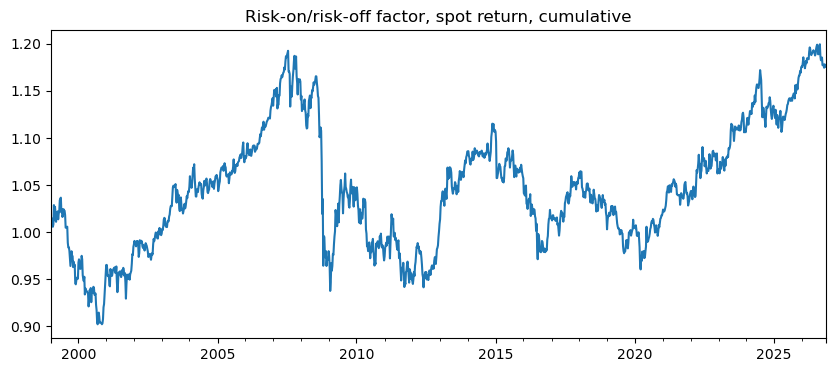

In [24]:
# The factor is the equal-weight basket of all 14 pairs, each held long.
# Summed over the pairs, the basket's net exposure is long EUR, GBP and AUD against short
# JPY and CHF (USD and CAD cancel out).
factor_spot = weekly_ret[helpers.ALL_PAIRS].mean(axis=1).rename("factor_spot")

# Net exposure to each currency, in units per pair (used for the carry below)
exposure = {}
for p in helpers.ALL_PAIRS:
    base, quote = p[:3], p[3:]
    exposure[base] = exposure.get(base, 0) + 1 / len(helpers.ALL_PAIRS)
    exposure[quote] = exposure.get(quote, 0) - 1 / len(helpers.ALL_PAIRS)
exposure = pd.Series(exposure).round(3)
print("Net exposure of the basket (per unit invested):")
print(exposure.to_string())

print()
print(f"Average weekly spot return: {factor_spot.mean():.4%}")
print(f"Weekly volatility:          {factor_spot.std():.4%}")

# A quick look: 2008 and March 2020 should be clearly negative (risk-off)
print("Return in 2008:      ", f"{(1 + factor_spot['2008']).prod() - 1:.1%}")
print("Return in March 2020:", f"{(1 + factor_spot['2020-03']).prod() - 1:.1%}")
(1 + factor_spot).cumprod().plot(figsize=(10, 4), title="Risk-on/risk-off factor, spot return, cumulative");

## 9. Rates and VIX

In [25]:
# Load each FRED series into one table
def load_fred(name):
    df = pd.read_csv(f"{helpers.RAW}/FRED_{name}.csv", index_col=0, parse_dates=True)
    return pd.to_numeric(df.iloc[:, 0], errors="coerce").rename(name)

fred = pd.DataFrame({name: load_fred(name) for name in helpers.FRED_SERIES})
fred = fred[fred.index >= "1998-01-01"]

# The CHF and JPY 3-month series start later (1999-07 and 2002-04). Before that we use
# each country's overnight rate, which was very close to the 3-month rate at the time.
for ccy in ("CHF", "JPY"):
    col = f"{ccy}_3M"
    call = load_fred(f"{ccy}_CALL").reindex(fred.index)
    before = fred.index < fred[col].first_valid_index()
    fred.loc[before, col] = call[before]

# Monthly rates: a value dated 1 August is only published weeks later.
# We shift every monthly series forward by 2 months, so it is used only from October.
rate_cols = [c for c in fred.columns if c != "VIX"]
rates = fred[rate_cols].dropna(how="all")
rates.index = rates.index + pd.DateOffset(months=2)

# Three series stop in January 2026, so their last value is carried forward.
rates = rates.reindex(pd.date_range(rates.index.min(), download_date, freq="MS")).ffill()

# Carry of the basket: the 3-month rate of each currency, weighted by the basket's exposure.
# Positive carry means the long currencies pay more interest than the short ones.
# It is in percent per year.
rates["carry"] = sum(exposure[ccy] * rates[f"{ccy}_3M"] for ccy in exposure.index)

# Bring the monthly rates to the weekly Friday dates (last known value on each Friday)
rates_weekly = rates.reindex(weekly_px.index, method="ffill")

# VIX is daily: take the value on each Friday (last available if Friday is missing)
vix_daily = fred["VIX"].dropna()
vix_weekly = vix_daily.reindex(weekly_px.index, method="ffill").rename("VIX")

# Total weekly return of the factor: spot move plus one week of carry
factor = (factor_spot + rates_weekly["carry"] / 100 / helpers.WEEKS_PER_YEAR).rename("factor")

print("Rates available from", rates_weekly.dropna().index.min().date())
print(f"Average carry: {rates['carry'].mean():.2f}% per year")
rates_weekly[["carry"]].join(vix_weekly).tail(3)

Rates available from 1999-01-08
Average carry: 1.30% per year


,carry,VIX
2026-10-30,1.092556,19.42
2026-11-06,1.092052,25.64
2026-11-13,1.092052,19.30


## 10. Daily factor returns and weekly realised volatility

Daily factor returns: 7266 days, saved to daily_factor.csv
Average realised volatility: 4.3% a year
Calmest week 0.3%, wildest week 35.5% (2008-10-31)


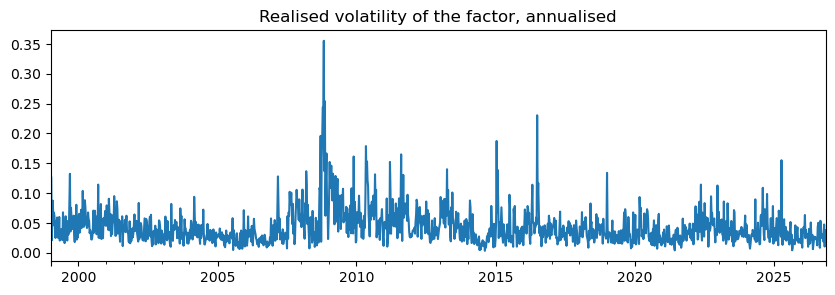

In [26]:
# The daily return of the factor: average daily return of the 14 pairs, plus one day of carry.
# (The carry series is weekly; we spread each Friday value over the following days.)
daily_spot = closes.pct_change()[helpers.ALL_PAIRS].mean(axis=1)
daily_carry = rates_weekly["carry"].reindex(closes.index, method="ffill") / 100 / 252
daily_factor = (daily_spot + daily_carry).rename("daily_factor").dropna()
daily_factor.to_csv(f"{helpers.PROCESSED}/daily_factor.csv")

# Realised volatility of a week: standard deviation of the daily returns inside that week,
# annualised (multiplied by the square root of 252 trading days). It measures how wild
# the week actually was, and it is known at that week's Friday close.
rv = daily_factor.resample("W-FRI").std() * np.sqrt(252)
rv = rv.rename("rv").reindex(weekly_px.index)

print("Daily factor returns:", len(daily_factor), "days, saved to daily_factor.csv")
print(f"Average realised volatility: {rv.mean():.1%} a year")
print(f"Calmest week {rv.min():.1%}, wildest week {rv.max():.1%} ({rv.idxmax().date()})")
rv.plot(figsize=(10, 3), title="Realised volatility of the factor, annualised");

## 11. Save and check

In [27]:
# Put everything in one weekly table
weekly = pd.concat([
    factor,
    factor_spot,
    rv,
    weekly_ret.add_prefix("ret_"),
    weekly_sp.pct_change().rename("sp500_ret"),
    rates_weekly,
    vix_weekly,
], axis=1)

# The first week has no return (nothing to compare with), and the rates start later
weekly = weekly.dropna()

weekly.to_csv(f"{helpers.PROCESSED}/weekly.csv")
print("Saved:", weekly.shape, "from", weekly.index[0].date(), "to", weekly.index[-1].date())

Saved: (1453, 34) from 1999-01-15 to 2026-11-13


In [28]:
# Checks. Each line stops the notebook with a message if it fails.

# No missing values
assert weekly.isna().sum().sum() == 0, "There are missing values in the weekly table"

# No date after the download date, and the last week is complete
assert weekly.index.max() < cutoff, "A week ends on or after the download date or the end date"
assert closes.index.max() >= weekly.index.max(), "The last week is not complete"

# Rebuilt AUDUSD matches the real one (weekly returns)
assert ret_corr > 0.99, f"Rebuilt AUDUSD does not match the real one (corr {ret_corr:.3f})"

# Rates are lagged: the first lagged date is 2 months after the first raw date
raw_first = fred[rate_cols].dropna(how="all").index.min()
assert rates.index.min() == raw_first + pd.DateOffset(months=2), "Rates are not lagged by 2 months"

# The factor falls in the two known risk-off episodes
assert (1 + factor_spot["2008"]).prod() - 1 < 0, "Factor did not fall in 2008"
assert (1 + factor_spot["2020-03"]).prod() - 1 < 0, "Factor did not fall in March 2020"

# Every Friday
assert all(weekly.index.dayofweek == 4), "Not every date is a Friday"

# FRED and Yahoo agree where both exist, and the history starts in 1999
assert basket_agreement > 0.95, "FRED and Yahoo disagree on the basket"
assert weekly.index.min() < pd.Timestamp("2000-01-01"), "History does not start in 1999"

# Realised volatility exists and is positive everywhere
assert (weekly["rv"] > 0).all(), "Realised volatility missing or not positive"

print("All checks passed")

All checks passed
